In [1]:
import numpy as np    # numerical python
import matplotlib     # matrix plotting library
import matplotlib.pyplot # python plotting
import skimage as sk  # sci-kit image
import skimage.io as skio # input/output
import scipy          # scientific python
import cv2            # opencv

import lib

In [2]:
def make_gaussian(sigma):
    ksize=int(np.ceil(sigma*3)//2*2+1)
    g=cv2.getGaussianKernel(ksize,sigma)
    g_T=np.transpose(g)
    g_filter=np.outer(g,g_T)
    return g_filter

In [3]:
def gaussian_stack(im,sigma,layers=6):
    gstack=[im]
    for i in range(layers):
        filter = np.asarray(make_gaussian(sigma)) 
        im = cv2.filter2D(gstack[0], -1, filter, borderType=cv2.BORDER_REFLECT)
        gstack.append(im)
        sigma*=2
    return gstack

In [4]:
def laplacian_stack(im,sigma,layers=6):
    gstack=gaussian_stack(im,sigma,layers)
    lstack=[]
    for i in range(len(gstack)-1):
        l=gstack[i]-gstack[i+1]
        lstack.append(l)
    lstack.append(gstack[-1])
    return lstack

In [5]:
def blend(im1,im2,mask):
    return im1*mask+im2*(1-mask)

In [6]:
def blend_full(im1,im2,mask,sigma,layers=6):
    b,g,r=cv2.split(im1)
    im1_bls,im1_gls,im1_rls=laplacian_stack(b,sigma,layers),laplacian_stack(g,sigma,layers),laplacian_stack(r,sigma,layers)
    b,g,r=cv2.split(im2)
    im2_bls,im2_gls,im2_rls=laplacian_stack(b,sigma,layers),laplacian_stack(g,sigma,layers),laplacian_stack(r,sigma,layers)
    mask_gs=gaussian_stack(mask,sigma*3,layers+1)[1:]
    layers+=1
    blended_b=np.zeros(np.shape(im1)[:-1])
    for i in range(layers):
        blended_b+=blend(im1_bls[i],im2_bls[i],mask_gs[i])
    blended_g=np.zeros(np.shape(im1)[:-1])
    for i in range(layers):
        blended_g+=blend(im1_gls[i],im2_gls[i],mask_gs[i])
    blended_r=np.zeros(np.shape(im1)[:-1])
    for i in range(layers):
        blended_r+=blend(im1_rls[i],im2_rls[i],mask_gs[i])
    im_out=cv2.merge([blended_b,blended_g,blended_r])
    return im_out

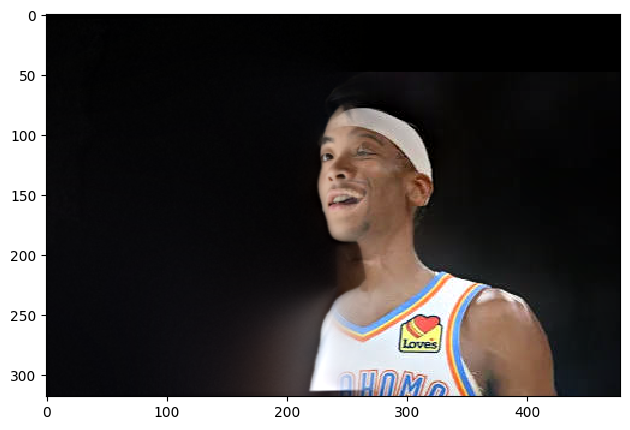

In [7]:
# 1. 讀取圖片並轉成 0.0 ~ 1.0 的浮點數
im1 = sk.img_as_float(skio.imread('results/chiahan_aligned_color.png')[:, :, :3])
im2 = sk.img_as_float(skio.imread('results/sga_aligned_color.png')[:, :, :3])
# 2. 注意 [:-1] 要在 np.zeros(...) 的括號裡面！
mask = np.zeros(np.shape(im1)[:-1])
mask[:, :len(mask[0]) // 11*6] = 1.0
# 3. 執行多解析度融合，並將結果限制在 0.0 ~ 1.0 之間
im_out = blend_full(im1, im2, mask, 5, 7)
im_out = np.clip(im_out, 0.0, 1.0)
skio.imshow(im_out)
skio.show()
lib.save_file('john_sga_blend.png', im_out)